In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/raw/oktoberfest.parquet")
s = df.set_index("date")["views"].asfreq("D")
s.describe()

count     4138.000000
mean      1891.893185
std       2305.182141
min        391.000000
25%        830.000000
50%       1069.000000
75%       1674.000000
max      26630.000000
Name: views, dtype: float64

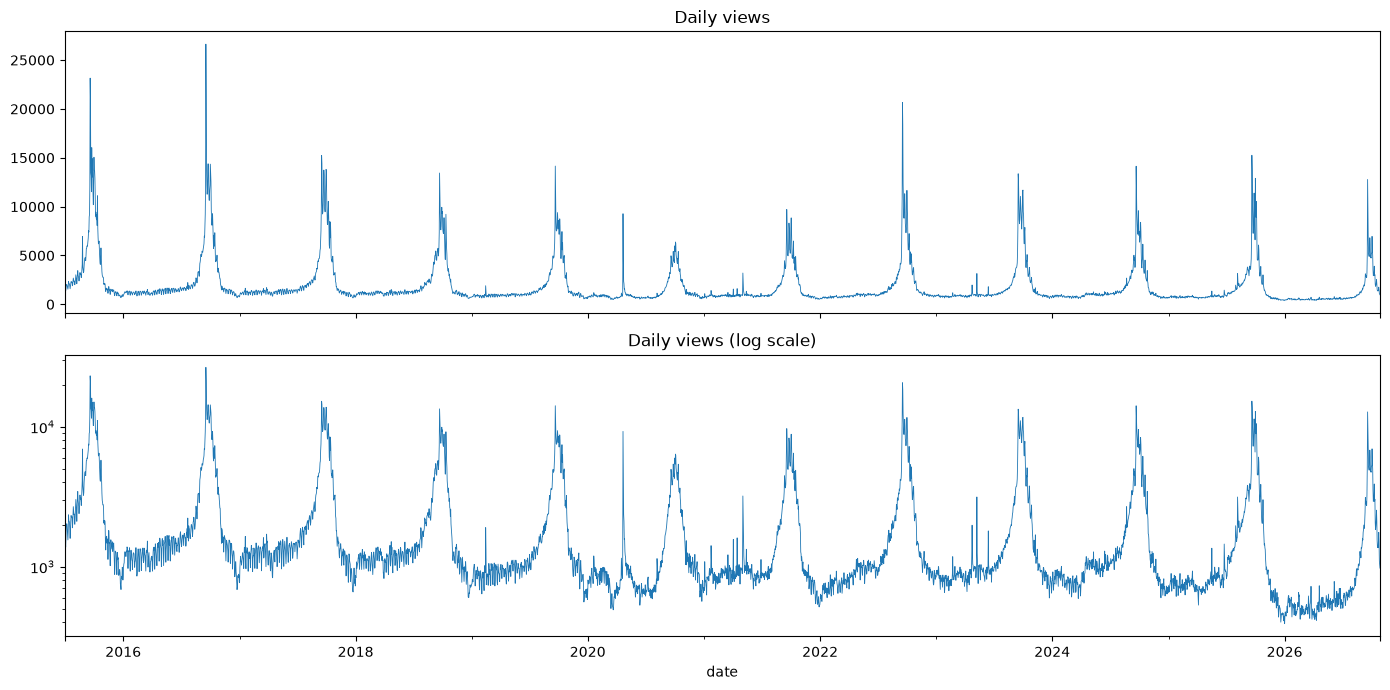

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
s.plot(ax=axes[0], lw=0.6, title="Daily views")
s.plot(ax=axes[1], lw=0.6, logy=True, title="Daily views (log scale)")
plt.tight_layout()

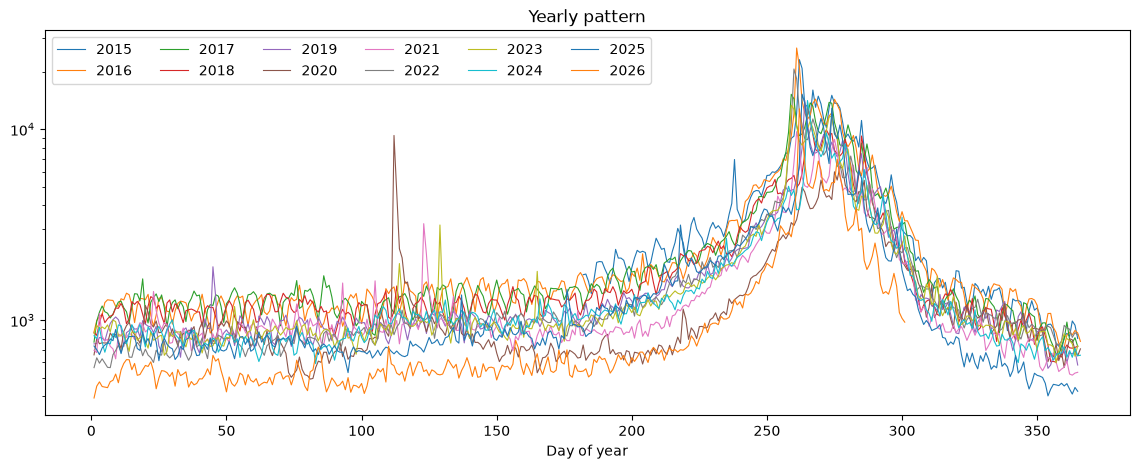

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
for year, g in s.groupby(s.index.year):
    ax.plot(g.index.day_of_year, g.values, lw=0.8, label=year)
ax.set_yscale("log")
ax.set_xlabel("Day of year")
ax.legend(ncol=6)
ax.set_title("Yearly pattern")
plt.show()

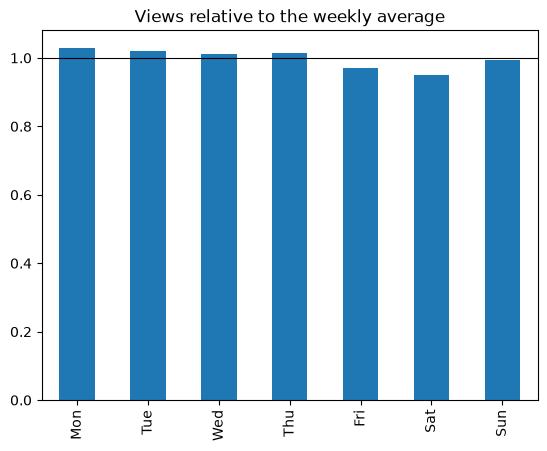

In [9]:
trend = s.rolling(7, center=True).mean()
ratio = (s / trend).dropna()

weekday = ratio.groupby(ratio.index.day_of_week).mean()
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday.plot(kind="bar", title="Views relative to the weekly average")
plt.axhline(1, color="black", lw=0.8)
plt.show()

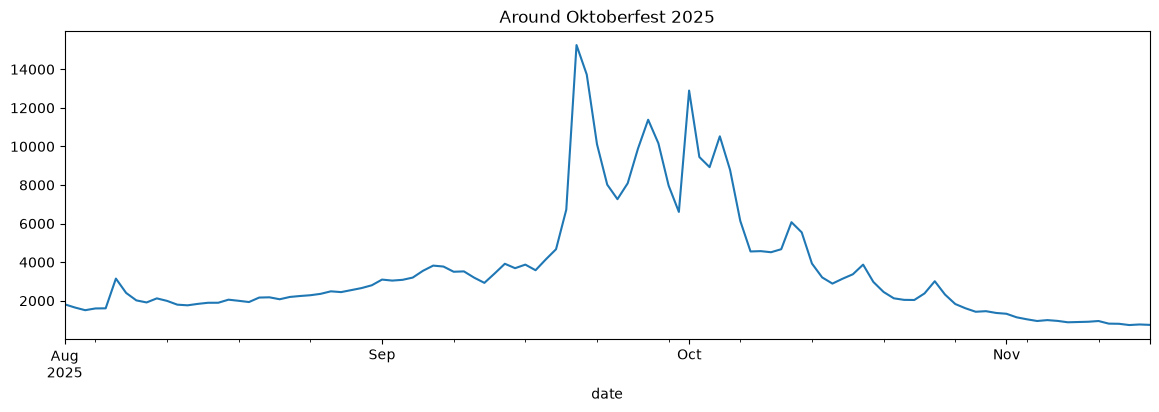

In [10]:
s["2025-08-01":"2025-11-15"].plot(figsize=(14, 4), title="Around Oktoberfest 2025")
plt.show()

## Key findings: Oktoberfest pageviews (Jul 2015 – Oct 2026)

**Data quality**
- 4,138 daily observations, no missing days.
- Views range from 391 to 26,630 per day (median ≈ 1,070).

**1. Trend**
- The off-season baseline is declining: from ~1,200–1,500 views/day (2016–17) to ~500 (2026).
- Peak levels are stable (~10–15k), so the peak-to-baseline ratio is growing.

**2. Yearly seasonality (dominant pattern)**
- Peaks are ~10–20× the baseline, around opening day (mid-September).
- Interest builds gradually from mid-July and decays over 4–6 weeks after the festival.
- The peak is asymmetric and has several sub-peaks (opening day, weekends, holidays).

**3. Structural break: COVID years**
- The festival was cancelled in 2020 and 2021; the peaks shrank (~6k and ~10k) but didn't vanish.
- Cancellation announcements appear as isolated spikes (late April 2020, early May 2021).
- 2022 rebounded strongly (~21k), so methods that copy last year's values would fail there.

**4. Weekly seasonality (weak)**
- Weekdays are ~2–3% above average, Friday/Saturday ~3–5% below.
- Small compared with the yearly effect, but may behave differently during the festival.

**Implications for modelling**
- Effects look multiplicative so training on logged values.
- Has weekly pattern so aligning same days by using a 364-day lag.
- A 365-day season is impractical for ETS/ARIMA so using MSTL or Fourier terms, Prophet handles it natively.
- The COVID years need explicit handling (exclude, flag, or average over several years).